# Eksploracyjna Analiza Danych (EDA): Ceny Nieruchomości w Ames, Iowa
1.
   Zmienną objaśnianą jest `SalePrice` – ciągła cecha liczbowa wyrażona w dolarach amerykańskich (USD).
2. **Rodzaje zmiennych**
   - **Liczbowe ciągłe:** metraże powierzchni (`GrLivArea`, `TotalBsmtSF`, `LotArea`, `1stFlrSF`), ceny.
   - **Liczbowe dyskretne:** liczba pokoi (`TotRmsAbvGrd`), łazienek (`FullBath`), miejsc w garażu (`GarageCars`), lata (`YearBuilt`, `YrSold`, `MoSold`).
   - **Jakościowe porządkowe (*ordinal*):** ocena jakości i stanu w skalach punktowych (`OverallQual`, `OverallCond`, `ExterQual`, `BsmtQual`).
   - **Jakościowe nominalne (*nominal*):** lokalizacja (`Neighborhood`), typ zabudowy (`BldgType`), styl architektoniczny (`HouseStyle`), rodzaj transakcji (`SaleCondition`).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

df = pd.read_csv('train.csv')
print(f'Wymiary zbioru danych: {df.shape[0]} wierszy oraz {df.shape[1]} kolumn.')
df.head(5)


Wymiary zbioru danych: 1460 wierszy oraz 81 kolumn.


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Przegląd struktury, typów kolumn i statystyk opisowych
Zgodnie z wymaganiami weryfikujemy typy wszystkich zmiennych (`df.dtypes`, `df.info()`) oraz wyznaczamy bazowe statystyki podsumowujące (`df.describe()`).


In [ ]:
type_counts = df.dtypes.value_counts()
print("Rozkład typów danych w zbiorze:")
print(type_counts)
print("-" * 50)

numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns

print(f"Liczba kolumn numerycznych: {len(numeric_cols)}")
print(f"Liczba kolumn kategorycznych/tekstowych: {len(categorical_cols)}")


Rozkład typów danych w zbiorze:
str        43
int64      35
float64     3
--------------------------------------------------
Liczba kolumn numerycznych: 38
Liczba kolumn kategorycznych/tekstowych: 43


In [ ]:
df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 2. Analiza braków danych i `NA`

> **Pułapka interpretacyjna:**  
> Domyślne wczytanie pliku przez `pd.read_csv()` zamienia tekstowy kod `"NA"` na wartość `NaN`.  
> Dokumentacja zbioru (`data_description.txt`) mówi, dla wielu cech kod `NA` jest formalną kategorią oznaczającą brak danego elementu:
> - `PoolQC = NA` $\rightarrow$ brak basenu (*No Pool*)
> - `MiscFeature = NA` $\rightarrow$ brak dodatkowych cech typu kort tenisowy, szopa (*None*)
> - `Alley = NA` $\rightarrow$ brak dostępu do alejki (*No alley access*)
> - `Fence = NA` $\rightarrow$ brak ogrodzenia (*No Fence*)
> - `FireplaceQu = NA` $\rightarrow$ brak kominka (*No Fireplace*)
> - `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond = NA` $\rightarrow$ brak garażu (*No Garage*)
> - `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1/2 = NA` $\rightarrow$ brak piwnicy (*No Basement*)


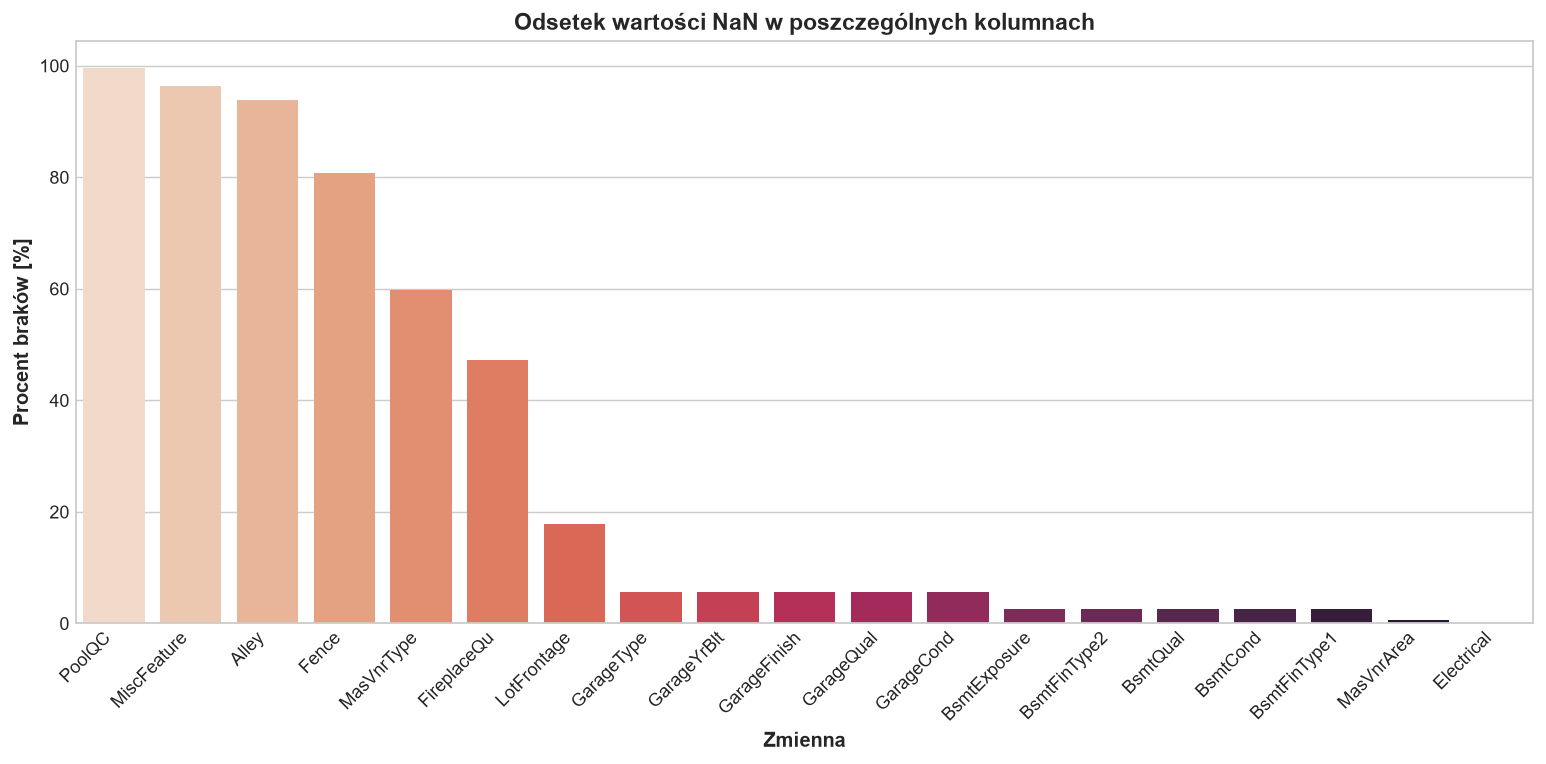

,Brakujące wartości,Procent braków [%]
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [ ]:
missing_counts = df.isnull().sum()
missing_data = pd.DataFrame({
    'Brakujące wartości': missing_counts[missing_counts > 0],
    'Procent braków [%]': (missing_counts[missing_counts > 0] / len(df)) * 100
}).sort_values(by='Brakujące wartości', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    x=missing_data.index,
    y=missing_data['Procent braków [%]'],
    hue=missing_data.index,
    palette='rocket_r',
    legend=False,
    ax=ax
)
plt.xticks(rotation=45, ha='right')
plt.title('Odsetek wartości NaN w poszczególnych kolumnach')
plt.ylabel('Procent braków [%]')
plt.xlabel('Zmienna')
plt.tight_layout()
plt.show()

missing_data


## 3. Szczegółowa analiza zmiennej docelowej (`SalePrice`)

W tej sekcji odpowiadamy na pytania postawione na slajdzie 46:
1. **Jaki jest rozkład cen? Czy rozkład jest symetryczny czy skośny?**
2. **Czy ceny mają rozkład normalny?**
3. **Jak kształtują się relacje średniej i mediany?**
4. **Gdzie występują wartości odstające (*outliers*) i co oznaczają najdroższe nieruchomości?**
5. **Precyzyjne wyliczenie miar pozycyjnych: $\text{Min}$, $\text{Max}$, Średnia, Mediana, $Q_1$, $Q_3$, $IQR$.**


In [ ]:
target = df['SalePrice']

min_val = target.min()
max_val = target.max()
mean_val = target.mean()
median_val = target.median()
q1_val = target.quantile(0.25)
q3_val = target.quantile(0.75)
iqr_val = q3_val - q1_val
skew_val = target.skew()
kurt_val = target.kurt()
outlier_upper_fence = q3_val + 1.5 * iqr_val
outlier_count = (target > outlier_upper_fence).sum()

stats_summary = pd.DataFrame({
    'Miara statystyczna': [
        'Minimalna cena (Min)',
        'Pierwszy kwartyl (Q1)',
        'Mediana (Q2)',
        'Średnia arytmetyczna',
        'Trzeci kwartyl (Q3)',
        'Maksymalna cena (Max)',
        'Rozstęp ćwiartkowy (IQR)',
        'Górna granica odstająca (Q3 + 1.5 IQR)',
        'Liczba transakcji odstających (> górna granica)',
        'Współczynnik skośności (Skewness)',
        'Kurtoza (Kurtosis)'
    ],
    'Wartość': [
        f"${min_val:,.2f}",
        f"${q1_val:,.2f}",
        f"${median_val:,.2f}",
        f"${mean_val:,.2f}",
        f"${q3_val:,.2f}",
        f"${max_val:,.2f}",
        f"${iqr_val:,.2f}",
        f"${outlier_upper_fence:,.2f}",
        f"{outlier_count} domów ({outlier_count/len(df)*100:.2f}%)",
        f"{skew_val:.4f}",
        f"{kurt_val:.4f}"
    ]
})

stats_summary


Miara statystyczna,Wartość
Minimalna cena (Min),"$34,900.00"
Pierwszy kwartyl (Q1),"$129,975.00"
Mediana (Q2),"$163,000.00"
Średnia arytmetyczna,"$180,921.20"
Trzeci kwartyl (Q3),"$214,000.00"
Maksymalna cena (Max),"$755,000.00"
Rozstęp ćwiartkowy (IQR),"$84,025.00"
Górna granica odstająca (Q3 + 1.5 IQR),"$340,037.50"
Liczba transakcji odstających (> górna granica),61 domów (4.18%)
Współczynnik skośności (Skewness),1.8829


### Eksperyment z histogramami cen (bins = 10, 30, 50) i wykres pudełkowy
Porównujemy postać histogramu dla różnej liczby przedziałów (bins) oraz zestawiamy go z wykresem pudełkowym pokazującym wartości odstające.


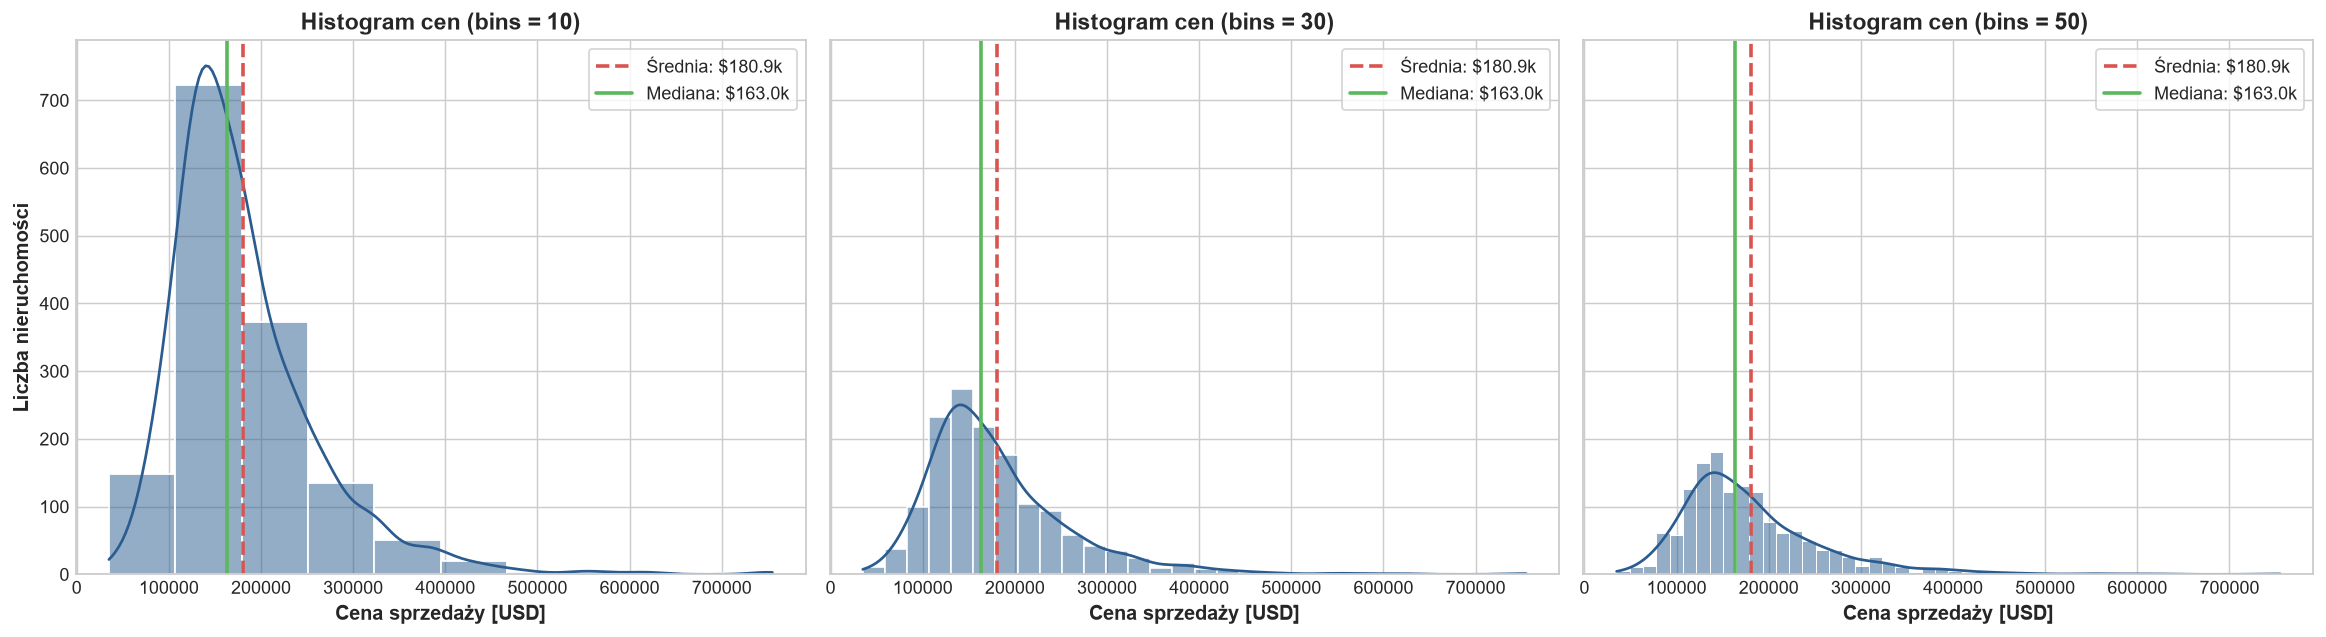

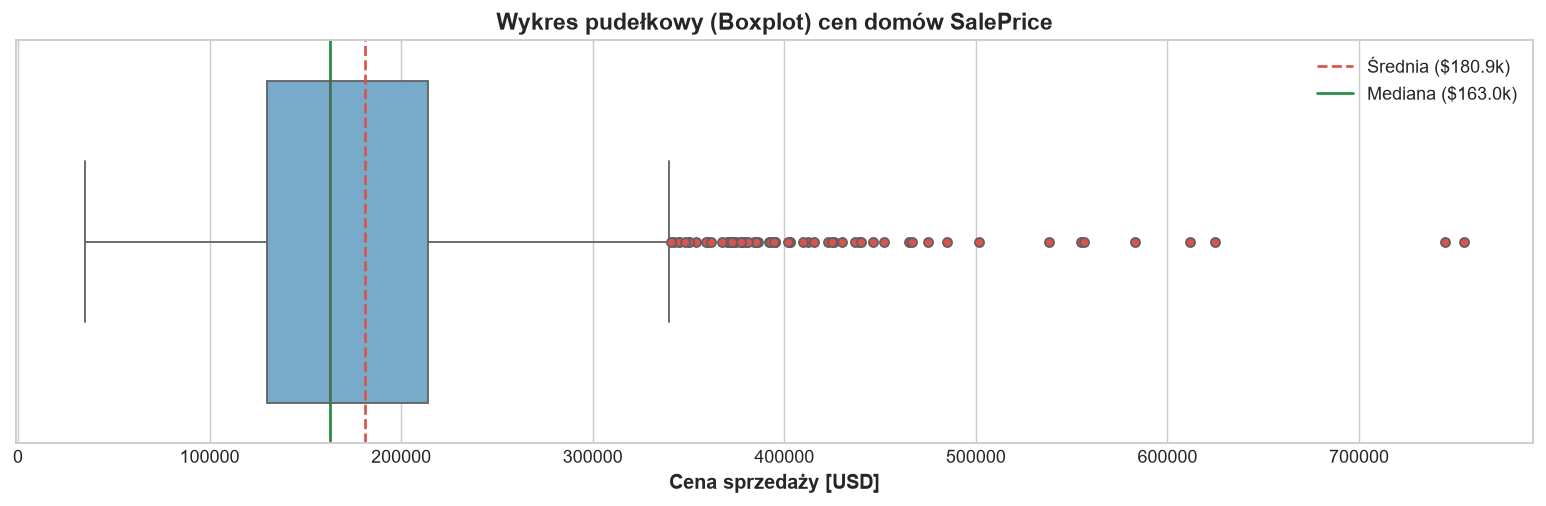

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
bins_list = [10, 30, 50]

for ax, b in zip(axes, bins_list):
    sns.histplot(df['SalePrice'], bins=b, kde=True, ax=ax, color='#2b5c8f', edgecolor='white')
    ax.axvline(mean_val, color='#d9534f', linestyle='--', linewidth=2, label=f'Średnia: ${mean_val/1000:.1f}k')
    ax.axvline(median_val, color='#5cb85c', linestyle='-', linewidth=2, label=f'Mediana: ${median_val/1000:.1f}k')
    ax.set_title(f'Histogram cen (bins = {b})')
    ax.set_xlabel('Cena sprzedaży [USD]')
    ax.set_ylabel('Liczba nieruchomości')
    ax.legend(frameon=True)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(x=df['SalePrice'], ax=ax, color='#6baed6', flierprops={'markerfacecolor': '#d9534f', 'markersize': 5})
ax.axvline(mean_val, color='#d9534f', linestyle='--', label=f'Średnia (${mean_val/1000:.1f}k)')
ax.axvline(median_val, color='#238b45', linestyle='-', label=f'Mediana (${median_val/1000:.1f}k)')
ax.set_title('Wykres pudełkowy (Boxplot) cen domów SalePrice')
ax.set_xlabel('Cena sprzedaży [USD]')
ax.legend()
plt.tight_layout()
plt.show()


### Wnioski z analizy rozkładu zmiennej docelowej:
1. **Asymetria prawostronna (prawostronna skośność):**  
   Współczynnik skośności wynosi **1.88** (wyraźnie $> 0$). Wykres nie jest symetryczny.
2. **Relacja średniej i mediany:**  
   Średnia arytmetyczna (**$180,921.20**) jest wyraźnie wyższa od mediany (**$163,000.00**). Różnica niemal 18 tys. USD wynika z faktu, że średnia jest wrażliwa na wartości skrajne i jest "ciągnięta w prawo" przez prawy ogon luksusowych domów.
3. **Brak rozkładu normalnego:**  
   Rozkład cechuje się wyraźną skośnością i podwyższoną kurtozą (6.54 – rozkład leptokurtyczny). W uczeniu maszynowym standardową praktyką będzie zastosowanie transformacji logarytmicznej: $\log(1 + \text{SalePrice})$.
4. **Wartości odstające:**  
   Aż 61 nieruchomości przekracza próg $Q_3 + 1.5\times IQR$ ($340,037.50). Są to luksusowe rezydencje, których cena jednostkowa i specyfikacja odbiega od typowego rynku mieszkaniowego w Ames.


## 4. Wykres pudełkowy jakości domu (`OverallQual`) i analiza anomalii

Na slajdach 35, 40 i 41 omówiono zagadkę:  
**Jak to możliwe, że domy o najwyższej ocenie jakości wykończenia (ocena 10 na 10) zostały sprzedane poniżej 200 000 USD?**  


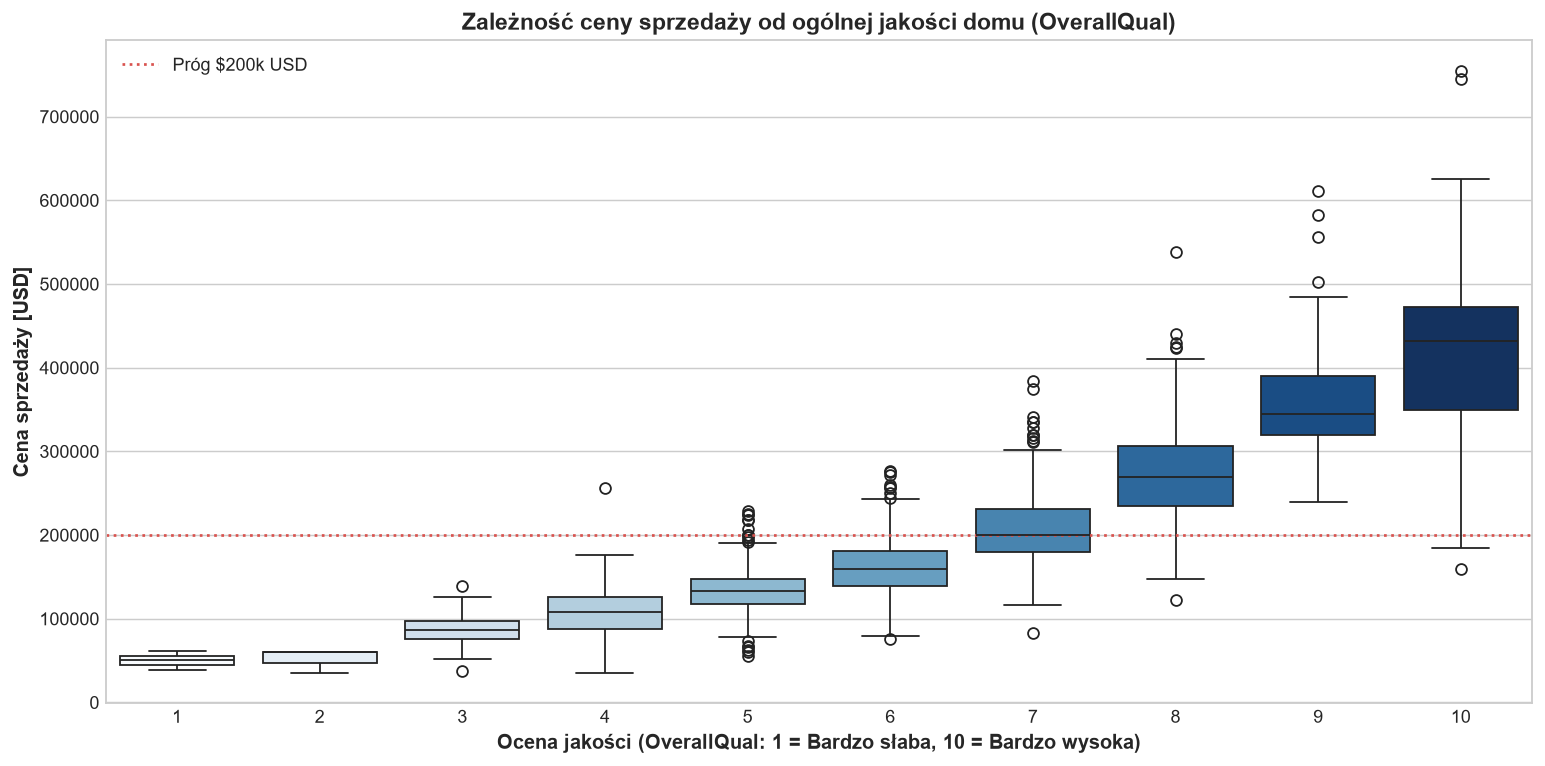

Id,OverallQual,SalePrice,GrLivArea,TotalBsmtSF,YearBuilt,SaleType,SaleCondition
524,10,184750,4676,3138,2007,New,Partial
1299,10,160000,5642,6110,2008,New,Partial


In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(x='OverallQual', y='SalePrice', data=df, hue='OverallQual', palette='Blues', legend=False, ax=ax)
ax.axhline(200000, color='#d9534f', linestyle=':', label='Próg $200k USD')
ax.set_title('Zależność ceny sprzedaży od ogólnej jakości domu (OverallQual)')
ax.set_xlabel('Ocena jakości (OverallQual: 1 = Bardzo słaba, 10 = Bardzo wysoka)')
ax.set_ylabel('Cena sprzedaży [USD]')
ax.legend()
plt.tight_layout()
plt.show()

anomalous_quality_10 = df[(df['OverallQual'] == 10) & (df['SalePrice'] < 200000)][
    ['Id', 'OverallQual', 'SalePrice', 'GrLivArea', 'TotalBsmtSF', 'YearBuilt', 'SaleType', 'SaleCondition']
]
anomalous_quality_10


### Wyjaśnienie anomalii domów z oceną 10 (Slajd 41):
1. Domy o **Id = 524** oraz **Id = 1299** posiadają ocenę 10 i powierzchnię mieszkalną odpowiednio **4676** oraz **5642 stóp²** (są to bezwzględnie **dwa największe domy w całym zbiorze danych**).
2. Obie transakcje mają status `SaleCondition = Partial` (sprzedaż częściowa / dom w trakcie realizacji budowy) oraz `SaleType = New`.
3. Kwota sprzedaży nie reprezentuje zatem rynkowej ceny w pełni wykończonej nieruchomości, lecz transakcję deweloperską na etapie budowy.
4. **Zalecenie prof. De Cocka:** Sam autor zbioru zaleca usunięcie obserwacji o powierzchni mieszkalnej powyżej 4000 stóp kwadratowych jako nietypowych transakcji nierynkowych, a nie jedynie dlatego, że „odstają na wykresie”.


## 5. Wykres słupkowy cechy kategorycznej: Instalacja elektryczna (`Electrical`)

Zgodnie ze slajdem 36 sprawdzamy rozkład typów instalacji elektrycznej oraz zależność od ceny sprzedaży.


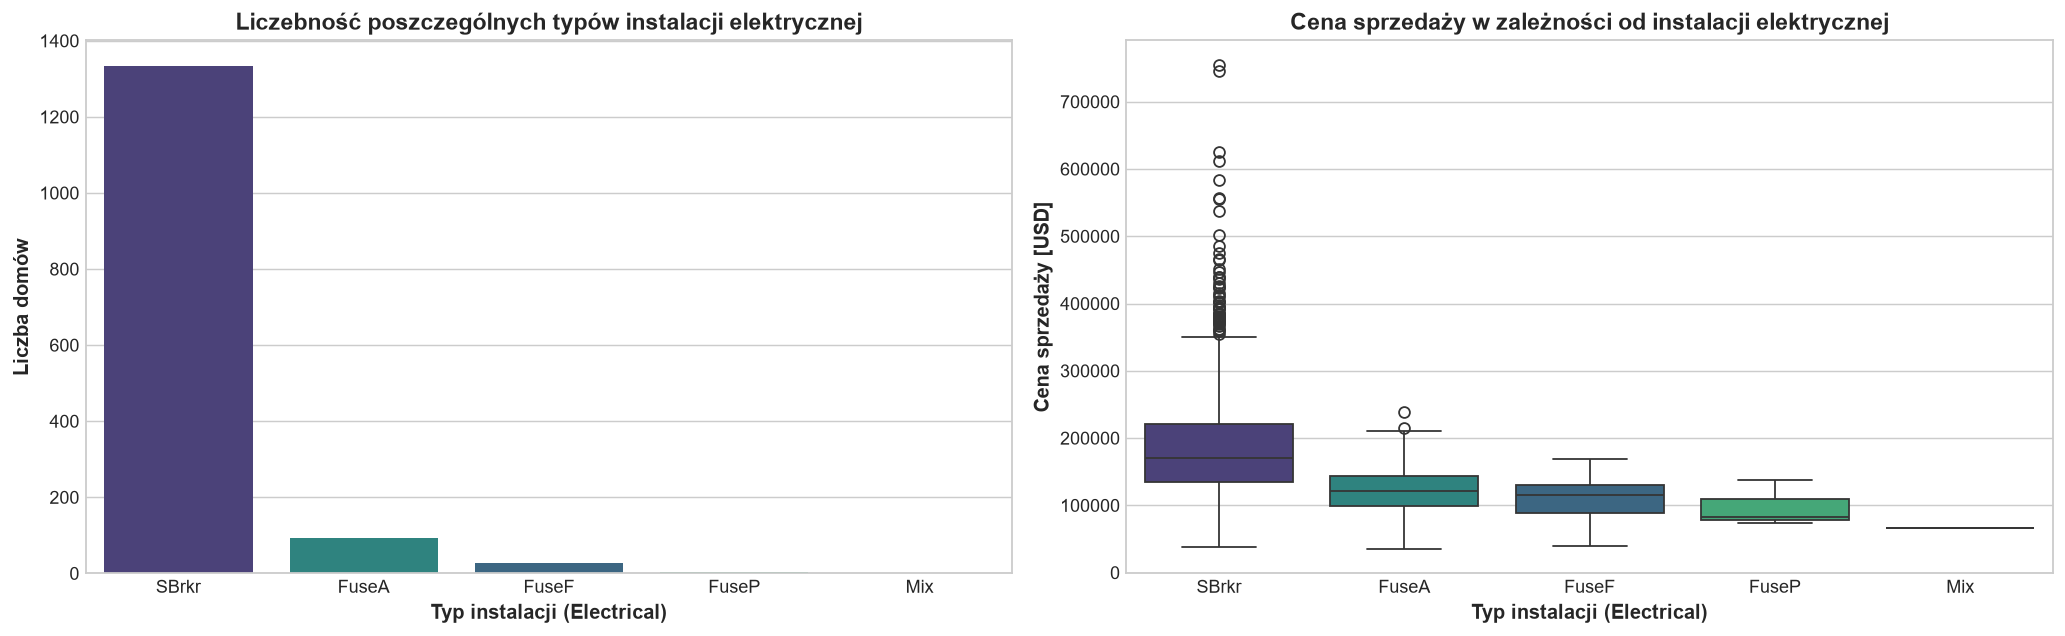

,count,median,mean,std
Electrical,,,,
FuseA,94,121250.0,122196.893617,37511.376615
FuseF,27,115000.0,107675.444444,30636.507376
FuseP,3,82000.0,97333.333333,34645.827070
Mix,1,67000.0,67000.000000,NaN
SBrkr,1334,170000.0,186825.113193,79856.458326


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

order_elec = df['Electrical'].value_counts().index
sns.countplot(
    x='Electrical',
    data=df,
    order=order_elec,
    hue='Electrical',
    palette='viridis',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Liczebność poszczególnych typów instalacji elektrycznej')
axes[0].set_xlabel('Typ instalacji (Electrical)')
axes[0].set_ylabel('Liczba domów')

sns.boxplot(
    x='Electrical',
    y='SalePrice',
    data=df,
    order=order_elec,
    hue='Electrical',
    palette='viridis',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Cena sprzedaży w zależności od instalacji elektrycznej')
axes[1].set_xlabel('Typ instalacji (Electrical)')
axes[1].set_ylabel('Cena sprzedaży [USD]')

plt.tight_layout()
plt.show()

electrical_summary = df.groupby('Electrical')['SalePrice'].agg(['count', 'median', 'mean', 'std'])
electrical_summary


### Wnioski dotyczące instalacji elektrycznej:
1. **Dominacja jednej kategorii:** Ponad 91% domów (1334 obserwacje) ma standardową, nowoczesną instalację `SBrkr` (*Standard Circuit Breakers & Romex*).
2. **Wpływ rzadkich kategorii:** Przestarzałe bezpieczniki topikowe (`FuseA`, `FuseF`, `FuseP`) wiążą się ze zdecydowanie niższą ceną nieruchomości (mediana dla `FuseP` to zaledwie 82 tys. USD).
3. **Ostrożność statystyczna:** W próbie jest zaledwie 1 dom z instalacją `Mix` oraz 3 domy z `FuseP`. Wyciąganie twardych wniosków uogólniających z tak małych podgrup niesie wysokie ryzyko błędu małej próby.


## 6. Trendy czasowe i sezonowość sprzedaży (wykres liniowy)

Na slajdzie 37 postawiono obserwację o sezonowości sprzedaży nieruchomości na przestrzeni roku i miesięcy.


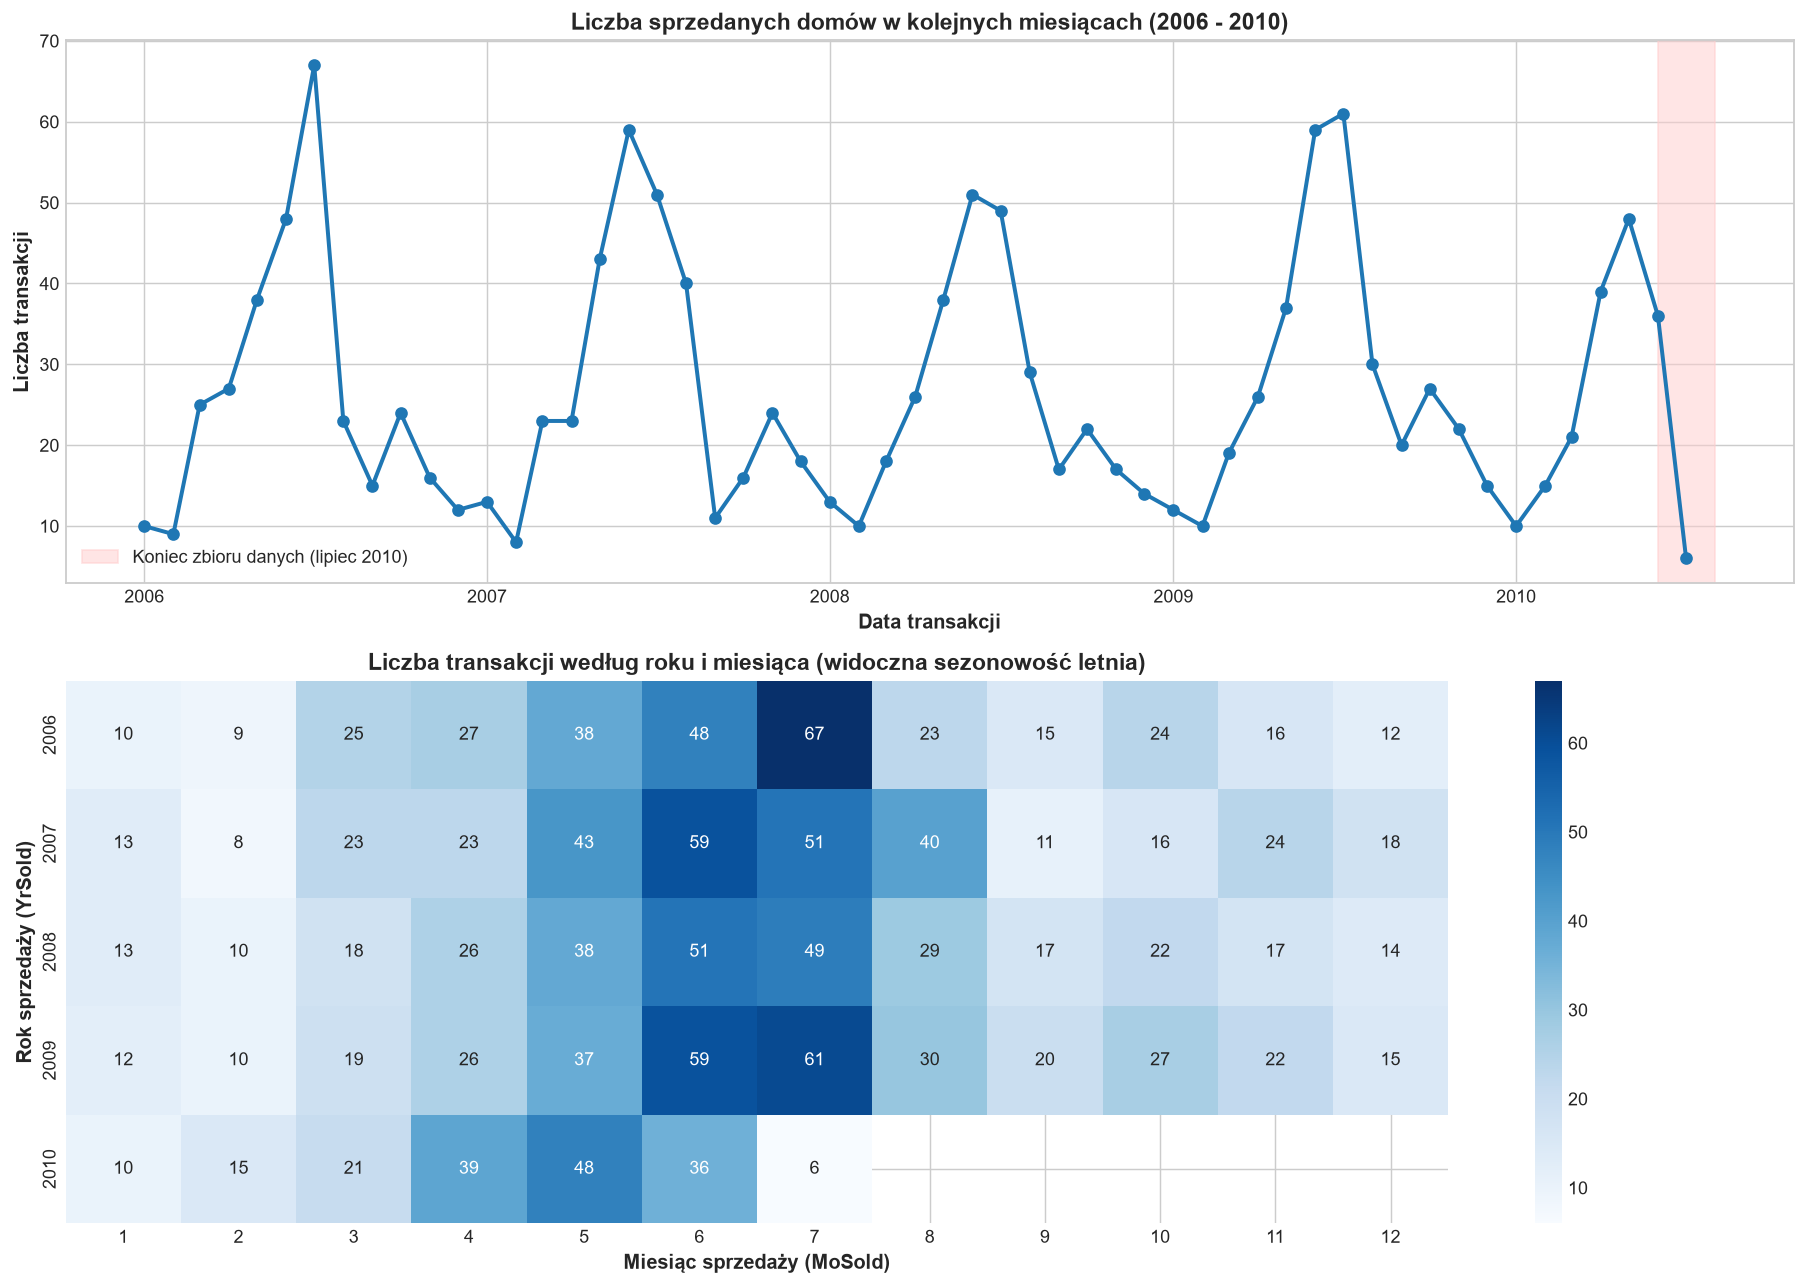

In [ ]:
monthly_sales = df.groupby(['YrSold', 'MoSold']).size().reset_index(name='Transactions')
monthly_sales['Period'] = pd.to_datetime(monthly_sales['YrSold'].astype(str) + '-' + monthly_sales['MoSold'].astype(str) + '-01')
monthly_sales = monthly_sales.sort_values('Period')

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(monthly_sales['Period'], monthly_sales['Transactions'], marker='o', color='#1f77b4', linewidth=2.2)
axes[0].set_title('Liczba sprzedanych domów w kolejnych miesiącach (2006 - 2010)')
axes[0].set_xlabel('Data transakcji')
axes[0].set_ylabel('Liczba transakcji')
axes[0].axvspan(pd.to_datetime('2010-06-01'), pd.to_datetime('2010-08-01'), color='#ffcccc', alpha=0.5, label='Koniec zbioru danych (lipiec 2010)')
axes[0].legend()

pivot_season = df.pivot_table(index='YrSold', columns='MoSold', values='Id', aggfunc='count')
sns.heatmap(pivot_season, cmap='Blues', annot=True, fmt='g', ax=axes[1])
axes[1].set_title('Liczba transakcji według roku i miesiąca (widoczna sezonowość letnia)')
axes[1].set_xlabel('Miesiąc sprzedaży (MoSold)')
axes[1].set_ylabel('Rok sprzedaży (YrSold)')

plt.tight_layout()
plt.show()


### Wnioski z analizy trendu czasowego:
1. **Silna sezonowość roczna:** W każdym roku występuje ten sam cykliczny wzorzec – najniższa aktywność rynkowa przypada na miesiące zimowe (styczeń–luty, ok. 10 transakcji), po czym następuje gwałtowny wzrost osiągający szczyt w maju, czerwcu i lipcu (ponad 50–60 transakcji miesięcznie).
2. **Pozorny spadek w 2010 roku:** Na końcu wykresu liniowego widoczny jest stromy spadek transakcji. **Nie oznacza on załamania rynku nieruchomości**, lecz wynika wyłącznie z faktu, że zbiór danych treningowych kończy się w **lipcu 2010 roku** (dane za drugą połowę 2010 roku nie były zbierane).


## 7. Weryfikacja hipotezy: „Większe domy są droższe”

Na slajdzie 47 zdefiniowano hipotezę badawczą:
- Znajdź zmienne związane z powierzchnią (`Area` oraz `SF`).
- Sprawdź wykres punktowy powierzchni mieszkalnej (`GrLivArea`) vs `SalePrice`. Czy zależność jest liniowa? Czy występują dziwne obserwacje?
- Sprawdź, czy powierzchnia działki (`LotArea`) ma taki sam wpływ jak powierzchnia domu.
- Porównaj różne rodzaje powierzchni – która ma najsilniejszy związek z ceną?


Zmienne związane z powierzchnią w zbiorze:
['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']


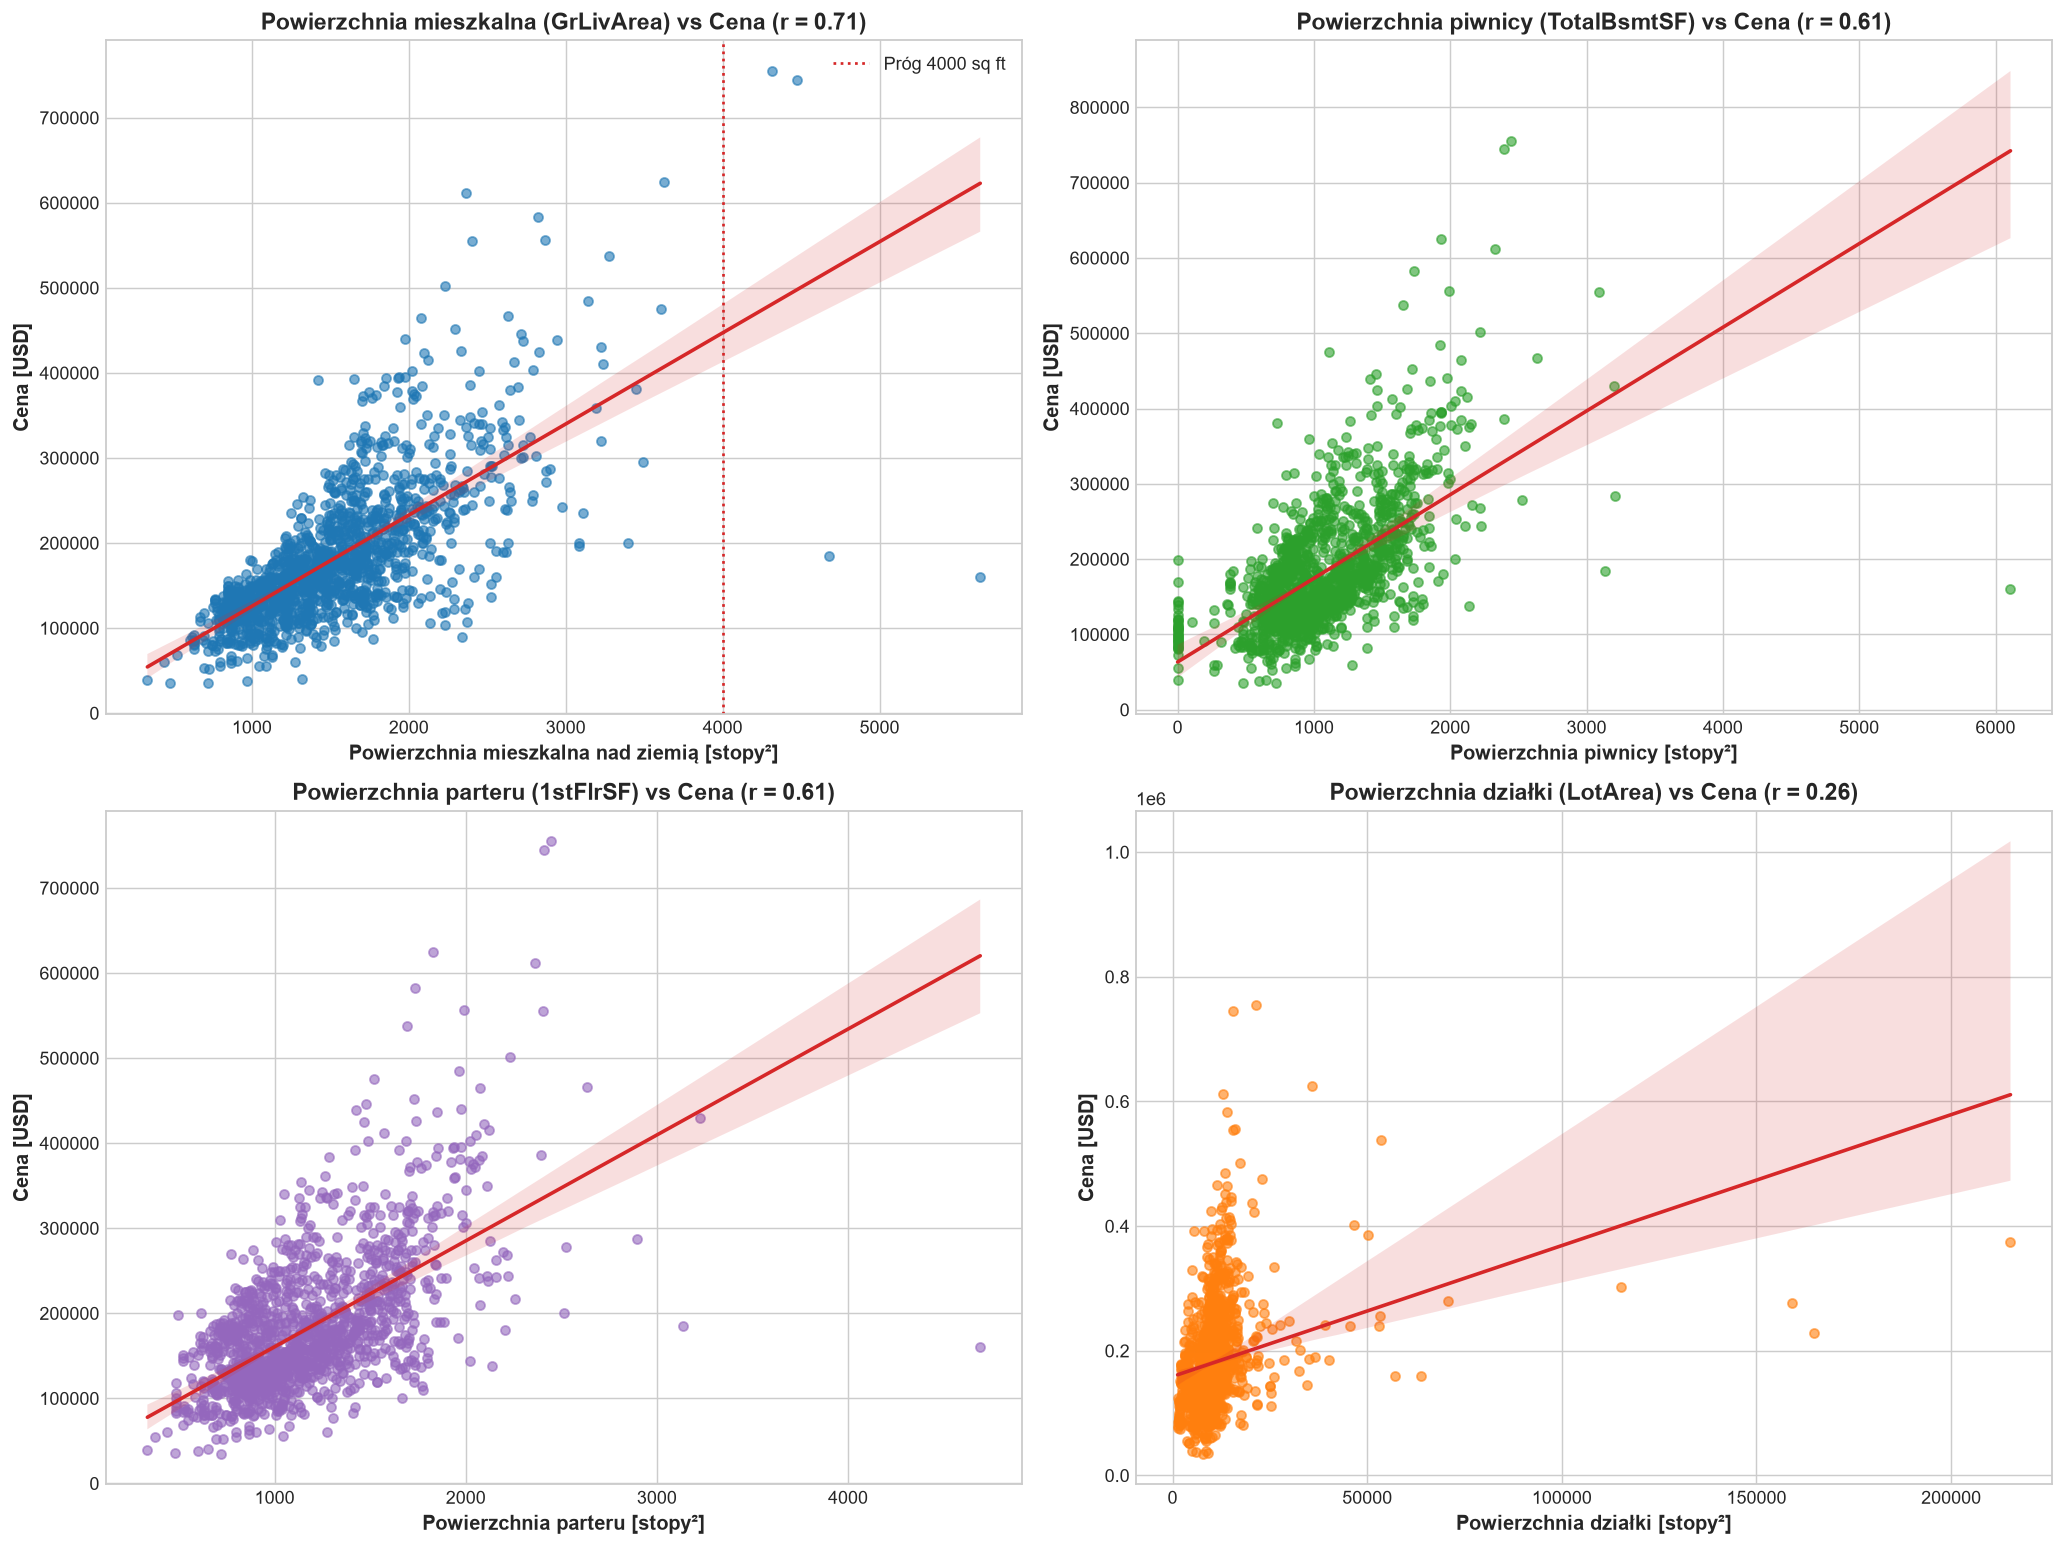

Cecha powierzchni,Korelacja Pearsona z SalePrice
SalePrice,1.000000
GrLivArea,0.708624
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
MasVnrArea,0.477493
BsmtFinSF1,0.386420
WoodDeckSF,0.324413
2ndFlrSF,0.319334
OpenPorchSF,0.315856


In [ ]:
area_cols = [c for c in df.columns if ('Area' in c or 'SF' in c) and df[c].dtype in [np.int64, np.float64]]
print("Zmienne związane z powierzchnią w zbiorze:")
print(area_cols)

corr_matrix = df[area_cols + ['SalePrice']].corr()['SalePrice'].sort_values(ascending=False)
corr_df = pd.DataFrame({
    'Cecha powierzchni': corr_matrix.index,
    'Korelacja Pearsona z SalePrice': corr_matrix.values
}).reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. GrLivArea vs SalePrice
sns.regplot(
    x='GrLivArea', y='SalePrice', data=df, ax=axes[0, 0],
    color='#1f77b4', scatter_kws={'alpha': 0.6, 's': 25}, line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[0, 0].axvline(4000, color='#d62728', linestyle=':', label='Próg 4000 sq ft')
axes[0, 0].set_title(f'Powierzchnia mieszkalna (GrLivArea) vs Cena (r = {corr_matrix["GrLivArea"]:.2f})')
axes[0, 0].set_xlabel('Powierzchnia mieszkalna nad ziemią [stopy²]')
axes[0, 0].set_ylabel('Cena [USD]')
axes[0, 0].legend()

# 2. TotalBsmtSF vs SalePrice
sns.regplot(
    x='TotalBsmtSF', y='SalePrice', data=df, ax=axes[0, 1],
    color='#2ca02c', scatter_kws={'alpha': 0.6, 's': 25}, line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[0, 1].set_title(f'Powierzchnia piwnicy (TotalBsmtSF) vs Cena (r = {corr_matrix["TotalBsmtSF"]:.2f})')
axes[0, 1].set_xlabel('Powierzchnia piwnicy [stopy²]')
axes[0, 1].set_ylabel('Cena [USD]')

# 3. 1stFlrSF vs SalePrice
sns.regplot(
    x='1stFlrSF', y='SalePrice', data=df, ax=axes[1, 0],
    color='#9467bd', scatter_kws={'alpha': 0.6, 's': 25}, line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[1, 0].set_title(f'Powierzchnia parteru (1stFlrSF) vs Cena (r = {corr_matrix["1stFlrSF"]:.2f})')
axes[1, 0].set_xlabel('Powierzchnia parteru [stopy²]')
axes[1, 0].set_ylabel('Cena [USD]')

# 4. LotArea vs SalePrice
sns.regplot(
    x='LotArea', y='SalePrice', data=df, ax=axes[1, 1],
    color='#ff7f0e', scatter_kws={'alpha': 0.6, 's': 25}, line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[1, 1].set_title(f'Powierzchnia działki (LotArea) vs Cena (r = {corr_matrix["LotArea"]:.2f})')
axes[1, 1].set_xlabel('Powierzchnia działki [stopy²]')
axes[1, 1].set_ylabel('Cena [USD]')

plt.tight_layout()
plt.show()

corr_df


### Weryfikacja hipotezy i odpowiedzi na pytania ze slajdu 47:
1. **Czy zależność między metrażem a ceną jest wyraźna i liniowa?**  
   Tak, istnieje bardzo silny, dodatni związek liniowy pomiędzy powierzchnią mieszkalną `GrLivArea` a ceną sprzedaży ($r = 0.71$).
2. **Który rodzaj powierzchni ma najsilniejszy związek z ceną?**  
   - **`GrLivArea` (powierzchnia mieszkalna nad poziomem gruntu):** $r = 0.71$ (**najsilniejszy wpływ** spośród wszystkich wymiarów powierzchniowych).
   - **`GarageArea` (powierzchnia garażu):** $r = 0.62$
   - **`TotalBsmtSF` (całkowita powierzchnia piwnicy):** $r = 0.61$
   - **`1stFlrSF` (powierzchnia pierwszego piętra):** $r = 0.61$
3. **Czy powierzchnia działki (`LotArea`) ma taki sam wpływ jak powierzchnia domu?**  
   **Zdecydowanie NIE.** Korelacja `LotArea` z ceną wynosi zaledwie $r = 0.26$. Kupujący w mieście Ames płacą przede wszystkim za przestrzeń użytkową samego budynku, a wielkość gruntu ma drugorzędne znaczenie (dodatkowo rozkład `LotArea` zawiera ekstremalne działki o powierzchni kilkudziesięciu tysięcy stóp, które nie przekładają się proporcjonalnie na wyższą cenę).
4. **Dziwne obserwacje na wykresie `GrLivArea` vs `SalePrice`:**  
   W prawym dolnym rogu wykresu (dla powierzchni $> 4000\text{ sq ft}$) wyraźnie odcinają się dwa punkty o ogromnym metrażu i rażąco niskiej cenie (< $200k). Są to zidentyfikowane wcześniej domy częściowo wykończone (`Partial`), które zaburzają linię regresji i powinny zostać wyłączone z modelowania standardowego rynku.


## 8. Podsumowanie i rekomendacje dla start-upu (AVM)

### Najważniejsze wnioski analityczne:
1. **Nieliniowość i skośność zmiennej docelowej:** Rozkład `SalePrice` ma prawostronny ogon i jest niesymetryczny. W modelach regresyjnych należy stosować $\log(\text{SalePrice})$.
2. **Kluczowe czynniki wartościotwórcze:**
   - **Ogólna jakość (`OverallQual`):** najsilniejszy pojedynczy predyktor ceny.
   - **Powierzchnia mieszkalna (`GrLivArea`):** najsilniejsza cecha metrażowa ($r = 0.71$).
   - **Powierzchnia pomocnicza:** wielkość garażu (`GarageArea`, $r=0.62$) oraz piwnicy (`TotalBsmtSF`, $r=0.61$).
3. **Ograniczenia zbioru (Domain & Scope):**
   - Zbiór dotyczy wyłącznie rynku w Ames (USA) i domów wolnostojących/szeregowców (`BldgType`). Brak mieszkań w blokach sprawia, że model nie może być bezpośrednio wdrożony na rynek europejski/polski bez zebrania dedykowanych danych.
   - Zbiór treningowy kończy się w lipcu 2010 r., co powoduje pozorny spadek na wykresach szeregów czasowych.
4. **Obsługa braków danych:**
   - Kolumny z brakami wynikającymi z nieposiadania danego elementu (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage...`, `Bsmt...`) należy zakodować jako osobną kategorię `"None"` lub wartość $0$ w cechach numerycznych (np. powierzchnia basenu = 0).
5. **Czyszczenie danych (*Data Cleaning*):**
   - Dwa domy o metrażu $> 4000\text{ stóp}^2$ ze sprzedażą częściową (`Partial`) powinny zostać usunięte z danych treningowych algorytmu wyceny, aby uniknąć błędnych prognoz dla dużych rezydencji.
